# 09 Clustervalidierung: Betriebszustand oder Jahreszeit?

- Notebook 05 findet in Betriebsstunden bei k=5 fünf Zustände; Stabilität, Saisonkontrolle und Ground-Truth-Join fehlten.
- Bilden die Stundencluster Betriebszustände ab oder nur Jahres- und Tageszeit? (Abschnitt 1 bis 7)
- Was ändern Feature-Gewichtung, BHKW-Ausschluss und Leistungsklassen? (Abschnitt 8 bis 10)
- Daten aus Notebook 00, Logik in `src/clustervalidierung.py`, Tests in `tests/test_clustervalidierung.py`.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.facecolor"] = "white"

ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "processed").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import clustervalidierung as cvl  # noqa: E402
from src import features as ft  # noqa: E402
from src import load_begehungen as lb  # noqa: E402
from src import load_data as ld  # noqa: E402
from src import nb00_daten as nb00  # noqa: E402
from src import weather  # noqa: E402
from src.load_data import _normalize_address  # noqa: E402

METER_DIR = ROOT / "data" / "processed" / "real_meters"
INSPECTIONS_PATH = ROOT / "data" / "processed" / "inspections_tidy.csv"
ZUORDNUNG_PATH = ROOT / "data" / "raw" / "Zuordnung.xlsx"
for pfad in (METER_DIR, INSPECTIONS_PATH, ZUORDNUNG_PATH):
    if not pfad.exists():
        raise FileNotFoundError(f"{pfad} nicht gefunden")

SEED = cvl.SEED
F = cvl.BETRIEBS_FEATURES
print("Merkmalsraum der Stundencluster:", F)

Merkmalsraum der Stundencluster: ['power_norm', 'flow_norm', 'dt', 'vl', 'rt']


## 1 Stundenpanel

- Merkmale wie in Notebook 05: `power_norm` und `flow_norm` (auf das stationseigene 95. Perzentil normiert, weil der Anschlusswert bei 15 von 100 Zählern fehlt), Spreizung, Vor- und Rücklauf.
- Ausgeschlossen: unter 100 vollständige Stunden (4 Zähler, darunter 58202380 aus dem Ausreißer-Trio) und Dauerstillstand (3 Zähler).
- 1.603.107 Betriebsstunden von 93 Zählern, 01.11.2021 bis 20.07.2026.

In [2]:
t0 = time.time()
panel, ausschluss = cvl.lade_stundenpanel(METER_DIR)
print(f"{len(panel):,} Betriebsstunden von {panel['Zählernummer'].nunique()} Zählern "
      f"({time.time() - t0:.0f} s)")
print(f"Zeitraum {panel['timestamp'].min():%Y-%m-%d} bis {panel['timestamp'].max():%Y-%m-%d}")
print("\nAusschlussbilanz:")
display(ausschluss)

1,603,107 Betriebsstunden von 93 Zählern (13 s)
Zeitraum 2021-11-01 bis 2026-07-20

Ausschlussbilanz:


,Zählernummer,n_stunden,n_zeilen_roh,grund
0,41566331,0,32342,weniger als 100 vollständige Stunden
1,41566332,0,32342,weniger als 100 vollständige Stunden
2,41628863,23675,32342,"p95(Leistung) = 0, Dauerstillstand"
3,41704231,23686,32342,"p95(Leistung) = 0, Dauerstillstand"
4,41704232,23684,32342,"p95(Leistung) = 0, Dauerstillstand"
5,48090145,0,32342,weniger als 100 vollständige Stunden
6,58202380,0,22167,weniger als 100 vollständige Stunden


In [3]:
temp = weather.load_outdoor_temperature(panel["timestamp"].min(), panel["timestamp"].max(),
                                        allow_download=False)
panel = cvl.mit_kontext(panel, temp)
print(f"Außentemperatur aus dem DWD-Cache, {temp['t_out'].isna().sum()} Fehlwerte "
      f"auf {len(temp):,} Stunden")
print(f"Stunden ohne Temperaturwert im Panel: {panel['t_out'].isna().mean():.4%}")
print("\nStundenanteil je Saisonsegment (das ist die Basisrate für alles Folgende):")
display(panel["season"].value_counts(normalize=True).round(3).to_frame("Anteil"))

Außentemperatur aus dem DWD-Cache, 9 Fehlwerte auf 41,312 Stunden
Stunden ohne Temperaturwert im Panel: 0.0135%

Stundenanteil je Saisonsegment (das ist die Basisrate für alles Folgende):


,Anteil
season,
sommer,0.332
kernwinter,0.275
uebergang_spaet,0.201
uebergang_frueh,0.192


## 2 Reproduktion der Partition aus Notebook 05

- Sweep k=2 bis 8 auf dem Panel aus `src/` mit dokumentierter Ausschlussregel.

Matrix: (1603107, 5)


,k,silhouette
0,2,0.306
1,3,0.355
2,4,0.385
3,5,0.405
4,6,0.359
5,7,0.355
6,8,0.361


299 s


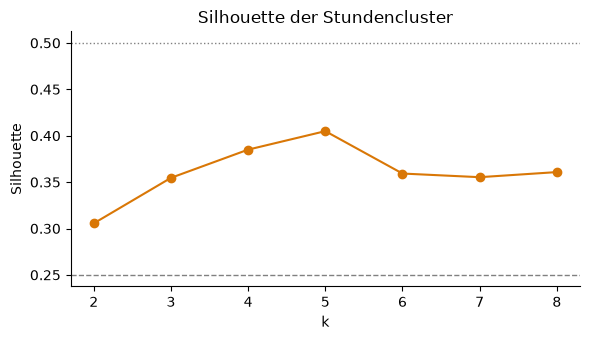

In [4]:
X = StandardScaler().fit_transform(panel[F])
print("Matrix:", X.shape)

t0 = time.time()
sweep = []
for k in range(2, 9):
    lab = cvl.fit_minibatch_kmeans(X, k, n_init=3)
    sweep.append({"k": k, "silhouette": cvl.silhouette_stichprobe(X, lab, 20000)})
sweep = pd.DataFrame(sweep)
display(sweep.round(3))
print(f"{time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(sweep["k"], sweep["silhouette"], marker="o", color="#D97706")
ax.axhline(0.25, color="grey", lw=1, ls="--")
ax.axhline(0.5, color="grey", lw=1, ls=":")
ax.set(title="Silhouette der Stundencluster", xlabel="k", ylabel="Silhouette")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

In [5]:
K = 5
labels = cvl.fit_minibatch_kmeans(X, K, n_init=10)
panel["cluster"] = labels
sil_voll = cvl.silhouette_stichprobe(X, labels, 20000)
print(f"k={K}: Silhouette {sil_voll:.3f}")

profil_voll = cvl.zentroid_profil(panel[F].to_numpy(), labels, F)
print("\nClusterprofile in Originaleinheiten (power_norm und flow_norm relativ zum "
      "stationseigenen p95, Temperaturen in °C):")
display(profil_voll.round(2))

k=5: Silhouette 0.404

Clusterprofile in Originaleinheiten (power_norm und flow_norm relativ zum stationseigenen p95, Temperaturen in °C):


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,0.33,0.22,33.72,67.09,33.32,392034,24.5
1,0.00,0.01,3.59,36.01,32.40,330042,20.6
2,0.07,0.10,11.82,66.92,55.06,408805,25.5
3,0.90,0.86,22.59,73.75,51.11,281021,17.5
4,0.20,0.78,3.80,75.23,71.39,191205,11.9


- Silhouette-Maximum bei k=5 (0,404 im finalen Lauf), k=4 mit 0,385 dahinter: Partition reproduziert, Clusternummern vertauscht.

| Cluster | Zustand | Kennzeichen | Anteil Stunden |
|---|---|---|---|
| 1 | Stillstand | Leistung praktisch 0, Vorlauf 36 °C | 21 % |
| 0 | effizienter Normalbetrieb | Spreizung 33,7 K, Rücklauf 33 °C | 25 % |
| 2 | Teillast | Leistung 0,07, Spreizung 11,8 K, Rücklauf 55 °C | 26 % |
| 3 | Hochlast | Leistung 0,90, Spreizung 22,6 K | 18 % |
| 4 | Verdacht hydraulischer Kurzschluss | Durchfluss 0,78 bei Leistung 0,20, Spreizung 3,8 K, Rücklauf 71,4 °C | 12 % |

- Cluster 4 passt zu Kurzschluss, offenem Ventil oder defekter Regelung; die Ursache zeigt die Messung nicht.

## 3 Stabilität

- Bootstrap-Refit wie in Notebook 04 (50 000 Zeilen je Lauf), Labels über das nächste Zentroid, ARI gegen die Referenz.

In [6]:
def fit_stunden(Xb, k):
    return cvl.fit_minibatch_kmeans(Xb, k, n_init=3)


t0 = time.time()
stab = []
for k in (3, 4, 5, 6):
    r = cvl.bootstrap_ari(fit_stunden, X, k, n_boot=25 if k == K else 15,
                          stichprobe=50000)
    stab.append({"k": k, **r.to_dict()})
stab = pd.DataFrame(stab)
display(stab.round(3))
print(f"{time.time() - t0:.0f} s")
ari_stunden = float(stab.loc[stab["k"] == K, "ari_mean"].iloc[0])
print(f"\nBootstrap-ARI bei k={K}: {ari_stunden:.3f} "
      "(Notebook 04 auf Stationsebene: 0,71 bzw. 0,60 bei k=3)")

,k,ari_mean,ari_std,ari_min,n_laeufe
0,3,0.596,0.243,0.295,15.0
1,4,0.851,0.145,0.595,15.0
2,5,0.853,0.149,0.535,25.0
3,6,0.700,0.116,0.478,15.0


64 s

Bootstrap-ARI bei k=5: 0.853 (Notebook 04 auf Stationsebene: 0,71 bzw. 0,60 bei k=3)


- k=5: ARI 0,853, k=4 gleichauf (0,851), k=3 (0,596) und k=6 (0,700) darunter; Streuung 0,15, schlechtester Lauf 0,54.
- Bei so vielen Punkten ist hohe Stabilität zu erwarten; sie zeigt Unabhängigkeit vom Seed, nicht fachliche Bedeutung.

## 4 Saison- und Tageszeitkontrolle

- Cramérs V und AMI gegen Saisonsegment, Monat und Stunde.
- Lift: Anteil eines Segments im Cluster durch seinen Anteil an allen Stunden (Basis: Sommer 33 %, Kernwinter 27,5 %).

In [7]:
basis = panel["season"].value_counts(normalize=True)
kt_saison = cvl.kontext_kreuztabelle(labels, panel["season"])
print("Anteil der Saisonsegmente je Cluster (Zeilensumme 1):")
display(kt_saison.round(3))
print("Lift gegen die Basisrate (1,0 = Cluster verteilt sich wie alle Stunden):")
display((kt_saison / basis).round(2))

kennwerte = pd.DataFrame([
    {"Kontextgröße": "Saisonsegment", "Cramers V": cvl.cramers_v(pd.crosstab(labels, panel["season"])),
     "AMI": adjusted_mutual_info_score(labels, panel["season"].astype(str))},
    {"Kontextgröße": "Monat", "Cramers V": cvl.cramers_v(pd.crosstab(labels, panel["monat"])),
     "AMI": adjusted_mutual_info_score(labels, panel["monat"].astype(str))},
    {"Kontextgröße": "Stunde des Tages", "Cramers V": cvl.cramers_v(pd.crosstab(labels, panel["stunde"])),
     "AMI": adjusted_mutual_info_score(labels, panel["stunde"].astype(str))},
])
display(kennwerte.round(3))

Anteil der Saisonsegmente je Cluster (Zeilensumme 1):


season,kernwinter,sommer,uebergang_frueh,uebergang_spaet
cluster,,,,
0,0.405,0.095,0.207,0.293
1,0.047,0.645,0.192,0.117
2,0.152,0.470,0.194,0.184
3,0.558,0.082,0.153,0.207
4,0.245,0.353,0.213,0.189


Lift gegen die Basisrate (1,0 = Cluster verteilt sich wie alle Stunden):


season,kernwinter,sommer,uebergang_frueh,uebergang_spaet
cluster,,,,
0,1.48,0.29,1.08,1.45
1,0.17,1.94,1.00,0.58
2,0.55,1.41,1.01,0.91
3,2.03,0.25,0.80,1.03
4,0.89,1.06,1.11,0.94


,Kontextgröße,Cramers V,AMI
0,Saisonsegment,0.310,0.107
1,Monat,0.294,0.095
2,Stunde des Tages,0.097,0.008


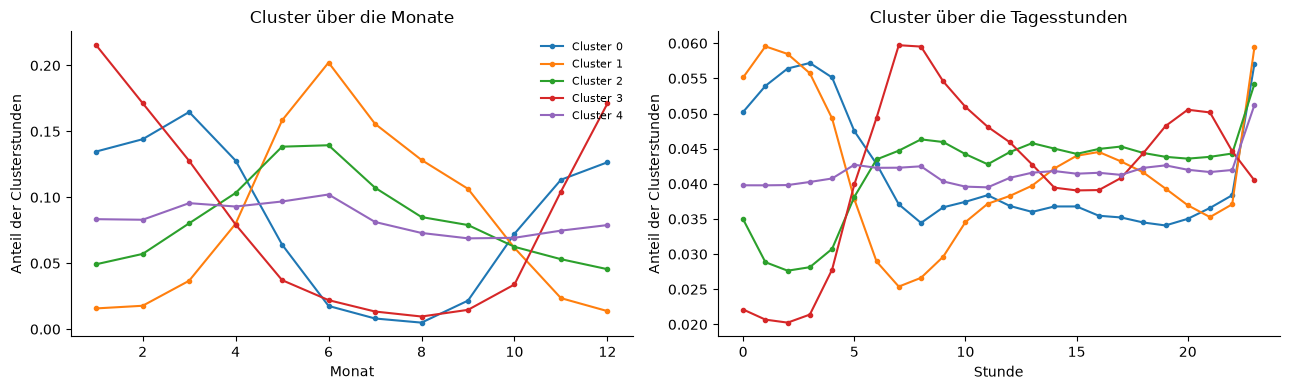

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
kt_monat = cvl.kontext_kreuztabelle(labels, panel["monat"])
kt_stunde = cvl.kontext_kreuztabelle(labels, panel["stunde"])
for ax, tab, titel, xlabel in [
        (axes[0], kt_monat, "Cluster über die Monate", "Monat"),
        (axes[1], kt_stunde, "Cluster über die Tagesstunden", "Stunde")]:
    for c in tab.index:
        ax.plot(tab.columns, tab.loc[c], marker="o", ms=3, label=f"Cluster {c}")
    ax.set(title=titel, xlabel=xlabel, ylabel="Anteil der Clusterstunden")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

- Tageszeit: Cramérs V 0,097, AMI 0,008, kein Tag-Nacht-Muster.
- Saison: Cramérs V 0,310, AMI 0,107; ein Teil der Partition ist Saison.
- Saisonal sind Stillstand (Lift Sommer 1,94), Hochlast (Kernwinter 2,03) und Normalbetrieb (Kernwinter 1,48).
- Kurzschlussverdacht in allen Segmenten nahe 1 (0,89 bis 1,11), nicht saisonal erklärbar.

## 5 Wie viel der Partition erklärt der Kontext allein?

- Flacher Entscheidungsbaum (Tiefe 4) sagt das Cluster nur aus Außentemperatur, Monat und Stunde vorher; Vergleich mit Trivialrate und mit den Clusterfeatures.

In [9]:
gruppen = {
    "nur Außentemperatur": ["t_out"],
    "nur Monat": ["monat"],
    "nur Stunde": ["stunde"],
    "Außentemperatur + Stunde": ["t_out", "stunde"],
    "Außentemperatur + Monat + Stunde": ["t_out", "monat", "stunde"],
    "Clusterfeatures (obere Marke)": F,
}
erklaerbarkeit = cvl.kontext_erklaerbarkeit(labels, panel, gruppen, max_depth=4,
                                            cv=5, stichprobe=150000)
display(erklaerbarkeit.round(3))

ref = float(erklaerbarkeit.loc[erklaerbarkeit["merkmale"] == "Clusterfeatures (obere Marke)",
                               "abstand"].iloc[0])
nur_t = float(erklaerbarkeit.loc[erklaerbarkeit["merkmale"] == "nur Außentemperatur",
                                 "abstand"].iloc[0])
print(f"\nDie Außentemperatur allein holt {nur_t / ref:.0%} des Abstands zur Trivialrate, "
      "den die Clusterfeatures erreichen.")

,merkmale,n,genauigkeit,trivialrate,abstand,ami
0,nur Außentemperatur,149972,0.378,0.253,0.126,0.116
1,nur Monat,150000,0.377,0.253,0.125,0.128
2,nur Stunde,150000,0.283,0.253,0.030,0.009
3,Außentemperatur + Stunde,149972,0.408,0.253,0.155,0.123
4,Außentemperatur + Monat + Stunde,149972,0.408,0.253,0.155,0.130
5,Clusterfeatures (obere Marke),150000,0.922,0.253,0.670,0.793



Die Außentemperatur allein holt 19% des Abstands zur Trivialrate, den die Clusterfeatures erreichen.


- Außentemperatur allein 0,378, Trivialrate 0,253, Clusterfeatures 0,922: die Temperatur holt 19 % des Abstands.
- Mit Monat und Stunde 0,408, kaum Zugewinn; die Partition steckt überwiegend nicht in der Witterung.

## 6 Gegenprobe im Kernwinter

- Nur Kernwinterstunden clustern (k=5 bis 7) und über die Zentroidprofile vergleichen.

In [10]:
win = panel[panel["season"] == "kernwinter"].reset_index(drop=True)
print(f"{len(win):,} Kernwinterstunden von {win['Zählernummer'].nunique()} Zählern")

Xw = StandardScaler().fit_transform(win[F])
sweep_w = pd.DataFrame([
    {"k": k, "silhouette": cvl.silhouette_stichprobe(Xw, cvl.fit_minibatch_kmeans(Xw, k, n_init=3), 20000)}
    for k in range(2, 9)])
display(sweep_w.round(3))

labels_w = cvl.fit_minibatch_kmeans(Xw, K, n_init=10)
sil_w = cvl.silhouette_stichprobe(Xw, labels_w, 20000)
r_w = cvl.bootstrap_ari(fit_stunden, Xw, K, n_boot=25, stichprobe=50000)
print(f"\nKernwinter, k={K}: Silhouette {sil_w:.3f}, Bootstrap-ARI {r_w['ari_mean']:.3f}")
print(f"Gesamtjahr,  k={K}: Silhouette {sil_voll:.3f}, Bootstrap-ARI {ari_stunden:.3f}")

profil_w = cvl.zentroid_profil(win[F].to_numpy(), labels_w, F)
display(profil_w.round(2))
print("Zuordnung der Winterprofile zum nächsten Profil des Gesamtjahreslaufs:")
display(cvl.zentroid_zuordnung(profil_w, profil_voll, F).round(3))
print(f"ARI Winterlabels gegen die Gesamtjahreslabels auf denselben Stunden: "
      f"{adjusted_rand_score(labels[(panel['season'] == 'kernwinter').to_numpy()], labels_w):.3f}")

440,228 Kernwinterstunden von 93 Zählern


,k,silhouette
0,2,0.317
1,3,0.309
2,4,0.309
3,5,0.313
4,6,0.286
5,7,0.287
6,8,0.286



Kernwinter, k=5: Silhouette 0.315, Bootstrap-ARI 0.624
Gesamtjahr,  k=5: Silhouette 0.404, Bootstrap-ARI 0.853


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,0.45,0.84,7.42,74.45,66.98,61755,14.0
1,0.46,0.29,35.58,68.52,32.90,157475,35.8
2,0.02,0.03,11.00,45.49,34.45,25921,5.9
3,0.98,0.88,24.31,73.98,49.63,121058,27.5
4,0.19,0.21,15.22,70.47,55.21,74019,16.8


Zuordnung der Winterprofile zum nächsten Profil des Gesamtjahreslaufs:


,cluster_a,cluster_b,distanz
0,0,4,0.902
1,1,0,0.502
2,2,1,1.017
3,3,3,0.306
4,4,2,0.628


ARI Winterlabels gegen die Gesamtjahreslabels auf denselben Stunden: 0.722


In [11]:
#traegt der Kurzschlussverdacht auch im Winter, wenn man k erhoeht?
for k in (6, 7):
    lk = cvl.fit_minibatch_kmeans(Xw, k, n_init=10)
    p = cvl.zentroid_profil(win[F].to_numpy(), lk, F)
    kandidat = p[(p["flow_norm"] > 0.4) & (p["dt"] < 10)]
    print(f"--- Kernwinter k={k}, Silhouette {cvl.silhouette_stichprobe(Xw, lk, 20000):.3f}")
    display(p.round(2))
    print("  Cluster mit hohem Durchfluss und Spreizung unter 10 K:",
          list(kandidat.index) or "keines")

--- Kernwinter k=6, Silhouette 0.295


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,1.08,0.93,28.73,73.48,44.71,77025,17.5
1,0.46,0.29,35.72,68.92,33.16,148626,33.8
2,0.04,0.04,13.79,47.74,33.91,32045,7.3
3,0.17,0.72,2.77,74.27,71.46,29942,6.8
4,0.72,0.80,15.09,74.34,59.21,91704,20.8
5,0.16,0.16,16.18,70.05,53.83,60886,13.8


  Cluster mit hohem Durchfluss und Spreizung unter 10 K: [3]
--- Kernwinter k=7, Silhouette 0.284


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,0.04,0.05,12.84,64.47,51.59,40098,9.1
1,0.92,0.94,18.57,74.33,55.73,96085,21.8
2,0.29,0.16,34.85,64.53,29.64,84196,19.1
3,0.31,0.66,7.07,73.87,66.76,63113,14.3
4,0.46,0.37,28.54,73.00,44.41,78967,17.9
5,0.98,0.69,37.18,72.09,34.86,64491,14.6
6,0.01,0.02,6.26,37.80,31.51,13278,3.0


  Cluster mit hohem Durchfluss und Spreizung unter 10 K: [3]


- 440.228 Stunden; Silhouette über k fast flach, bei k=5 0,315 und Bootstrap-ARI 0,624: innerhalb einer Jahreszeit schwächer und weniger stabil.
- Alle fünf Winterprofile haben ein Gegenstück im Gesamtjahr; ARI gegen die Gesamtjahreslabels 0,722.
- Kurzschlussverdacht schon bei k=5 eigenes Wintercluster (Spreizung 7,4 K, Rücklauf 67 °C, 14 %), bei k=6 in reiner Form (2,8 K, 71,5 °C, 7 %).
- Folgerung: übers ganze Jahr clustern, Saison als Kontext, Kernwinterlauf als Gegenprobe.

## 7 Ground-Truth-Join gegen die Begehungen

- Verbringen Stationen mit dokumentierter Maßnahme mehr Zeit in einem Zustand?
- Adress-Join über `_normalize_address` aus `src/load_data.py`; „mindestens eine Maßnahme“ trifft auf rund 80 % zu, das Label trennt wenig.

In [12]:
insp = pd.read_csv(INSPECTIONS_PATH)
gt = insp.groupby("address_norm").agg(n_begehungen=("address_norm", "size"),
                                      n_actions=("n_actions", "sum")).reset_index()
gt["massnahme"] = gt["n_actions"] > 0

anteile = panel.groupby("Zählernummer")["cluster"].value_counts(normalize=True).unstack(fill_value=0)
anteile.columns = [f"anteil_c{c}" for c in anteile.columns]

stationen = pd.read_csv(ROOT / "data" / "processed" / "hast_features.csv")[["Zählernummer", "address"]]
j = stationen.copy()
j["address_norm"] = j["address"].apply(_normalize_address)
j = j.merge(gt, on="address_norm", how="inner").merge(anteile, left_on="Zählernummer",
                                                      right_index=True, how="inner")
print(f"{len(j)} Stationen im Ground-Truth-Join, Basisrate 'mindestens eine Maßnahme' "
      f"{j['massnahme'].mean():.0%}")

zeilen = []
for spalte in anteile.columns:
    a = j.loc[j["massnahme"], spalte]
    b = j.loc[~j["massnahme"], spalte]
    rho, p_rho = stats.spearmanr(j[spalte], j["n_actions"])
    zeilen.append({"Cluster": spalte, "Median mit Maßnahme": a.median(),
                   "Median ohne Maßnahme": b.median(),
                   "Mann-Whitney p": stats.mannwhitneyu(a, b).pvalue,
                   "Spearman rho vs. n_actions": rho, "p": p_rho})
display(pd.DataFrame(zeilen).round(3))

56 Stationen im Ground-Truth-Join, Basisrate 'mindestens eine Maßnahme' 77%


,Cluster,Median mit Maßnahme,Median ohne Maßnahme,Mann-Whitney p,Spearman rho vs. n_actions,p
0,anteil_c0,0.295,0.315,0.362,-0.076,0.579
1,anteil_c1,0.224,0.169,0.221,0.086,0.530
2,anteil_c2,0.214,0.164,0.712,-0.019,0.887
3,anteil_c3,0.152,0.171,0.157,-0.223,0.099
4,anteil_c4,0.020,0.022,0.741,0.089,0.514


In [13]:
#Rangliste nach Zeit im Kurzschlussverdacht, Stationen nur ueber die Zaehlernummer
kurzschluss = profil_voll[(profil_voll["flow_norm"] > 0.4) & (profil_voll["dt"] < 8)].index
print("Cluster mit Kurzschlussverdacht:", list(kurzschluss))
spalte = f"anteil_c{int(kurzschluss[0])}"
rangliste = anteile[[spalte]].sort_values(spalte, ascending=False)
print(f"\nZähler mit mehr als 20 % der Stunden in diesem Zustand: "
      f"{int((anteile[spalte] > 0.2).sum())} von {len(anteile)}")
display(rangliste.head(15).round(3))
display(anteile[spalte].describe().round(3).to_frame("Verteilung über alle Zähler"))

Cluster mit Kurzschlussverdacht: [4]

Zähler mit mehr als 20 % der Stunden in diesem Zustand: 16 von 93


,anteil_c4
Zählernummer,
80912182,0.888
72167793,0.813
68956360,0.678
72167782,0.667
68956351,0.614
72135480,0.535
69513891,0.472
81062289,0.410
80912173,0.406


,Verteilung über alle Zähler
count,93.000
mean,0.110
std,0.192
min,0.000
25%,0.002
50%,0.021
75%,0.134
max,0.888


- 56 Stationen, Basisrate 77 %, nur 13 ohne Maßnahme; kein Clusteranteil mit p < 0,05 (kleinstes p 0,157).
- Kurzschlussverdacht: Mediane 2,0 % und 2,2 % gleichauf; bei 68956351 stand ein Ventil drei Jahre offen, die Reparatur steht nur im Freitext. Befund über die Labels.
- Rangliste nach Zeitanteil im Kurzschlussverdacht: 16 von 93 Zählern über 20 %, Spitze 80912182 (0,888) und 72167793 (0,813), 68956351 mit 61 % auf Platz 5.
- Taugt zur Priorisierung einer Prüfung vor Ort, nicht als Nachweis.

## 8 Feature-Gewichtung auf den Stationsprofilen

- Korrelierte Spalten zählen in K-Means dieselbe Richtung mehrfach, eine ungeplante Gewichtung.
- 21 numerische Stationsfeatures aus `src/features.py` über `nb00.stationsfeatures()`, Vorverarbeitung wie Notebook 04.
- Vergleich: alle Features gleich, Redundanzabbau ab |r| ≥ 0,8, PCA auf 90 % Varianz.

In [14]:
t0 = time.time()
nodes = ld.load_logical_nodes()
adressen = lb.meter_to_address()
#Zaehlerstaende der Nachlieferung ergaenzt, sonst fehlen Jahresenergie und Volllaststunden
feat = nb00.stationsfeatures(METER_DIR, nodes_df=nodes, address_map=adressen)
print(f"{len(feat)} Stationsprofile, {time.time() - t0:.0f} s")

NUM = [c for c in feat.columns if c not in ("Zählernummer", "address", "anschlusswert_kw")]
print(f"{len(NUM)} numerische Features")
roh = feat[NUM].replace([np.inf, -np.inf], np.nan)
print("\nAnteil fehlender Werte je Feature:")
display((roh.isna().mean() * 100).sort_values(ascending=False).round(1).to_frame("% fehlend"))

imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(roh), columns=NUM)
grenzen = imp.quantile([0.01, 0.99])
Xs = imp.clip(lower=grenzen.loc[0.01], upper=grenzen.loc[0.99], axis=1)

100 Stationsprofile, 25 s
21 numerische Features

Anteil fehlender Werte je Feature:


,% fehlend
p95_load_share,15.0
peak_load_share,15.0
dt_p10_loaded,6.0
dt_mean_loaded,6.0
dt_std_loaded,6.0
standby_dt,4.0
flow_short_cycle_power,2.0
volume_m3_year,2.0
rt_above_50_share_loaded,2.0
rt_p95,0.0


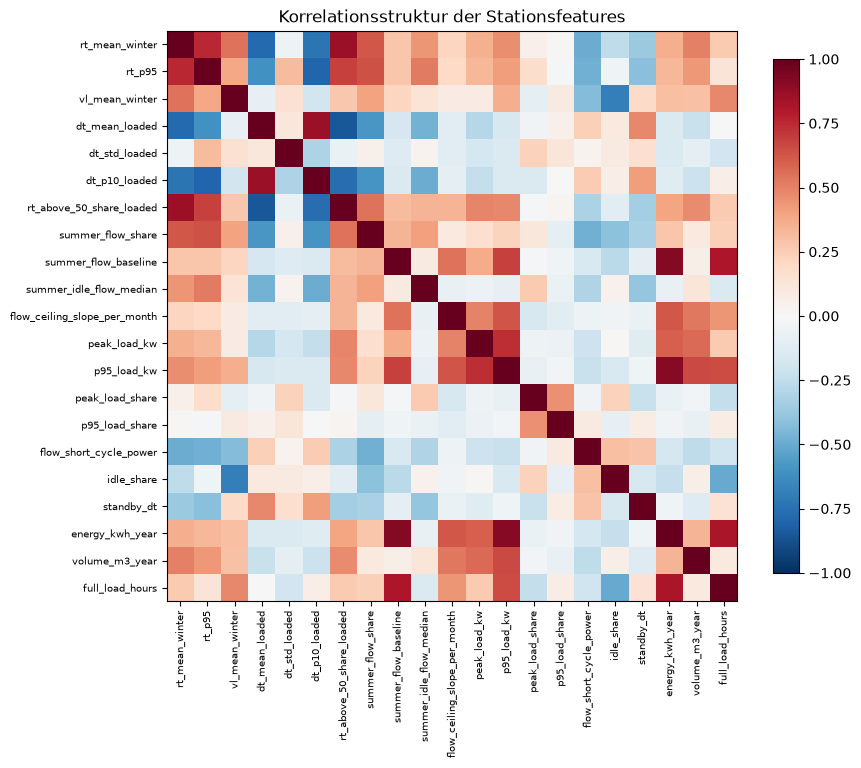

Paare mit |r| >= 0,8 - jedes davon zählt in der Distanz doppelt:


,Feature A,Feature B,r
3,summer_flow_baseline,energy_kwh_year,0.92
5,p95_load_kw,energy_kwh_year,0.91
1,dt_mean_loaded,dt_p10_loaded,0.87
0,rt_mean_winter,rt_above_50_share_loaded,0.86
2,dt_mean_loaded,rt_above_50_share_loaded,-0.85
6,energy_kwh_year,full_load_hours,0.82
4,summer_flow_baseline,full_load_hours,0.81


In [15]:
korr = Xs.corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(korr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM)), NUM, rotation=90, fontsize=7)
ax.set_yticks(range(len(NUM)), NUM, fontsize=7)
ax.set_title("Korrelationsstruktur der Stationsfeatures")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

oben = np.triu(np.ones(korr.shape), 1).astype(bool)
paare = [{"Feature A": korr.index[i], "Feature B": korr.columns[j], "r": korr.iat[i, j]}
         for i, j in zip(*np.where((korr.abs() >= 0.8) & oben))]
print("Paare mit |r| >= 0,8 - jedes davon zählt in der Distanz doppelt:")
display(pd.DataFrame(paare).sort_values("r", key=lambda s: s.abs(), ascending=False).round(2))

In [16]:
#fachliche Reihenfolge: die Achsen, auf denen eine Fehlerrangliste argumentiert,
#werden beim Redundanzabbau bevorzugt behalten
PRIORITAET = ["rt_mean_winter", "dt_mean_loaded", "summer_flow_baseline", "idle_share",
              "full_load_hours", "flow_short_cycle_power", "peak_load_share",
              "flow_ceiling_slope_per_month", "dt_std_loaded"]
auswahl, bilanz = cvl.redundanz_auswahl(Xs, schwelle=0.8, prioritaet=PRIORITAET)
print(f"{len(auswahl)} von {len(NUM)} Features bleiben:")
print(auswahl)
print("\nVerworfen, mit Grund:")
display(bilanz.round(2))

varianten = cvl.gewichtungsvarianten(Xs, NUM, auswahl=auswahl, pca_varianz=0.9)
for name, M in varianten.items():
    print(f"{name:14s} {M.shape[1]} Dimensionen")

17 von 21 Features bleiben:
['rt_mean_winter', 'dt_mean_loaded', 'summer_flow_baseline', 'idle_share', 'flow_short_cycle_power', 'peak_load_share', 'flow_ceiling_slope_per_month', 'dt_std_loaded', 'rt_p95', 'vl_mean_winter', 'summer_flow_share', 'summer_idle_flow_median', 'peak_load_kw', 'p95_load_kw', 'p95_load_share', 'standby_dt', 'volume_m3_year']

Verworfen, mit Grund:


,feature,redundant_zu,korrelation
0,full_load_hours,summer_flow_baseline,0.81
1,dt_p10_loaded,dt_mean_loaded,0.87
2,rt_above_50_share_loaded,rt_mean_winter,0.86
3,energy_kwh_year,summer_flow_baseline,0.92


alle gleich    21 Dimensionen
auswahl        17 Dimensionen
pca            9 Dimensionen


In [17]:
def fit_station(M, k):
    return KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(M).labels_


TRIO = {58202380, 66761022, 86792512}
zaehler = feat["Zählernummer"].to_numpy()

zeilen = []
for name, M in varianten.items():
    for k in (2, 3, 4, 5):
        lab = fit_station(M, k)
        r = cvl.bootstrap_ari(fit_station, M, k, n_boot=25)
        groessen = pd.Series(lab).value_counts().sort_index()
        kleinstes = groessen.idxmin()
        zeilen.append({
            "Weg": name, "k": k,
            "Silhouette": silhouette_score(M, lab),
            "Bootstrap-ARI": r["ari_mean"],
            "Clustergrößen": "/".join(str(int(v)) for v in groessen),
            "Trio im kleinsten Cluster": len(set(zaehler[lab == kleinstes]) & TRIO),
        })
vergleich = pd.DataFrame(zeilen)
display(vergleich.round(3))

,Weg,k,Silhouette,Bootstrap-ARI,Clustergrößen,Trio im kleinsten Cluster
0,alle gleich,2,0.317,0.543,72/28,3
1,alle gleich,3,0.281,0.766,67/7/26,3
2,alle gleich,4,0.283,0.820,32/2/5/61,2
3,alle gleich,5,0.214,0.611,26/2/5/19/48,2
4,auswahl,2,0.344,0.649,77/23,3
5,auswahl,3,0.308,0.707,20/73/7,3
6,auswahl,4,0.215,0.521,20/16/57/7,3
7,auswahl,5,0.270,0.595,20/5/10/63/2,2
8,pca,2,0.345,0.541,72/28,3
9,pca,3,0.315,0.807,67/7/26,3


In [18]:
ACHSEN = ["rt_mean_winter", "dt_mean_loaded", "summer_flow_baseline", "idle_share"]
referenz = fit_station(varianten["alle gleich"], 3)
for name, M in varianten.items():
    lab = fit_station(M, 3)
    p = feat.assign(cluster=lab).groupby("cluster")[ACHSEN].median()
    p["n_hast"] = pd.Series(lab).value_counts().sort_index()
    print(f"--- {name}, k=3, ARI gegen 'alle gleich': "
          f"{adjusted_rand_score(referenz, lab):.3f}")
    display(p.round(2))

--- alle gleich, k=3, ARI gegen 'alle gleich': 1.000


,rt_mean_winter,dt_mean_loaded,summer_flow_baseline,idle_share,n_hast
cluster,,,,,
0,42.28,27.74,0.0,0.29,67
1,63.07,15.70,0.0,0.44,7
2,55.87,15.63,52.5,0.24,26


--- auswahl, k=3, ARI gegen 'alle gleich': 0.788


,rt_mean_winter,dt_mean_loaded,summer_flow_baseline,idle_share,n_hast
cluster,,,,,
0,57.26,15.63,78.5,0.24,20
1,42.87,27.49,0.0,0.29,73
2,63.07,15.70,0.0,0.44,7


--- pca, k=3, ARI gegen 'alle gleich': 1.000


,rt_mean_winter,dt_mean_loaded,summer_flow_baseline,idle_share,n_hast
cluster,,,,,
0,42.28,27.74,0.0,0.29,67
1,63.07,15.70,0.0,0.44,7
2,55.87,15.63,52.5,0.24,26


- Sieben Featurepaare mit |r| ≥ 0,8, vor allem Größenachse (Jahresenergie, 95-Perzentil-Leistung, Volllaststunden) und Auskühlung.
- k=3: alle gleich Silhouette 0,281 und ARI 0,766, Auswahl (17 Features) 0,308 und 0,707, PCA (9 Komponenten) 0,315 und 0,807.
- PCA ergibt dieselbe Partition wie alle gleich (ARI 1,0), ist aber schlechter lesbar; die Auswahl verschiebt sie (ARI 0,79).
- Alle unter Silhouette 0,35, Ausreißer-Trio im kleinsten Cluster, Rest ein Kontinuum: die Gewichtung erklärt nicht die fehlenden Stationstypen.

## 9 Stationstypen und Leistungsklassen

- Zähler 86792512 ist laut `Zuordnung.xlsx` ein BHKW und gehört zum Ausreißer-Trio aus Notebook 01.
- Leistungsklassen über den Anschlusswert (`Nodes_Edges.ods`) mit Grenzen 5 und 10 kW, Parameter in `src/clustervalidierung.py`.

In [19]:
feat = cvl.mit_leistungsklasse(feat)
display(feat["leistungsklasse"].value_counts().sort_index().to_frame("Anzahl HAST"))
display(feat.groupby("leistungsklasse", observed=False)["anschlusswert_kw"]
        .describe().round(1))

vpin = pd.concat([pd.read_excel(ZUORDNUNG_PATH, sheet_name=s, dtype={"V-PIN": str})
                  [["Zählernummer", "V-PIN"]] for s in ("2024", "2025")])
vpin["Zählernummer"] = pd.to_numeric(vpin["Zählernummer"], errors="coerce")
bhkw = set(vpin.loc[vpin["V-PIN"] == "BHKW", "Zählernummer"].dropna().astype(int))
print("Als BHKW geführt:", sorted(bhkw))
display(feat.loc[feat["Zählernummer"].isin(bhkw),
                 ["Zählernummer", "anschlusswert_kw", "leistungsklasse",
                  "rt_mean_winter", "dt_mean_loaded", "energy_kwh_year"]].round(1))

,Anzahl HAST
leistungsklasse,
bis 5 kW,1
5-10 kW,52
über 10 kW,32
unbekannt,15


,count,mean,std,min,25%,50%,75%,max
leistungsklasse,,,,,,,,
bis 5 kW,1.0,5.0,NaN,5.0,5.0,5.0,5.0,5.0
5-10 kW,52.0,8.6,1.1,6.0,8.0,8.0,10.0,10.0
über 10 kW,32.0,31.6,85.8,11.0,12.8,14.0,17.5,500.0
unbekannt,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Als BHKW geführt: [86792512]


,Zählernummer,anschlusswert_kw,leistungsklasse,rt_mean_winter,dt_mean_loaded,energy_kwh_year
99,86792512,NaN,unbekannt,60.0,15.7,2105984.5


- Bis 5 kW 1 Station, 5 bis 10 kW 52, über 10 kW 32, ohne Anschlusswert 15 (darunter das BHKW).
- Nutzbar sind zwei Klassen plus die Gruppe ohne Anschlusswert; Grenzen bleiben fachlich festzulegen.

In [20]:
ohne_bhkw = (~feat["Zählernummer"].isin(bhkw)).to_numpy()
zeilen = []
for name, maske in [("alle Stationen", np.ones(len(feat), bool)), ("ohne BHKW", ohne_bhkw)]:
    M = StandardScaler().fit_transform(Xs[maske][auswahl])
    for k in (2, 3, 4):
        lab = fit_station(M, k)
        r = cvl.bootstrap_ari(fit_station, M, k, n_boot=25)
        zeilen.append({"Gruppe": name, "n": int(maske.sum()), "k": k,
                       "Silhouette": silhouette_score(M, lab),
                       "Bootstrap-ARI": r["ari_mean"],
                       "Clustergrößen": "/".join(str(int(v)) for v in
                                                 pd.Series(lab).value_counts().sort_index())})

for klasse in feat["leistungsklasse"].cat.categories:
    maske = (feat["leistungsklasse"] == klasse).to_numpy() & ohne_bhkw
    if maske.sum() < 15:
        zeilen.append({"Gruppe": f"nur {klasse}", "n": int(maske.sum()), "k": np.nan,
                       "Silhouette": np.nan, "Bootstrap-ARI": np.nan,
                       "Clustergrößen": "zu klein zum Clustern"})
        continue
    M = StandardScaler().fit_transform(Xs[maske][auswahl])
    for k in (2, 3):
        lab = fit_station(M, k)
        r = cvl.bootstrap_ari(fit_station, M, k, n_boot=25)
        zeilen.append({"Gruppe": f"nur {klasse}", "n": int(maske.sum()), "k": k,
                       "Silhouette": silhouette_score(M, lab),
                       "Bootstrap-ARI": r["ari_mean"],
                       "Clustergrößen": "/".join(str(int(v)) for v in
                                                 pd.Series(lab).value_counts().sort_index())})
display(pd.DataFrame(zeilen).round(3))

,Gruppe,n,k,Silhouette,Bootstrap-ARI,Clustergrößen
0,alle Stationen,100,2.0,0.344,0.649,77/23
1,alle Stationen,100,3.0,0.308,0.707,20/73/7
2,alle Stationen,100,4.0,0.215,0.521,20/16/57/7
3,ohne BHKW,99,2.0,0.347,0.544,77/22
4,ohne BHKW,99,3.0,0.314,0.757,20/73/6
5,ohne BHKW,99,4.0,0.247,0.606,20/11/6/62
6,nur bis 5 kW,1,NaN,NaN,NaN,zu klein zum Clustern
7,nur 5-10 kW,52,2.0,0.226,0.432,34/18
8,nur 5-10 kW,52,3.0,0.187,0.510,29/1/22
9,nur über 10 kW,32,2.0,0.613,0.451,31/1


In [21]:
M = StandardScaler().fit_transform(Xs[ohne_bhkw][auswahl])
lab3 = fit_station(M, 3)
tab = pd.crosstab(pd.Series(lab3, name="cluster"),
                  feat.loc[ohne_bhkw, "leistungsklasse"].astype(str))
print("Cluster gegen Leistungsklasse, ohne BHKW, k=3:")
display(tab)
print(f"Cramers V: {cvl.cramers_v(tab):.3f}")

Cluster gegen Leistungsklasse, ohne BHKW, k=3:


leistungsklasse,5-10 kW,bis 5 kW,unbekannt,über 10 kW
cluster,,,,
0,9,0,1,10
1,43,1,8,21
2,0,0,5,1


Cramers V: 0.383


## 10 Leistungsklassen auf Stundenebene

- Auf Stundenebene stehen je Klasse rund 100 000 bis 960 000 Stunden; vorab der Lauf ohne BHKW.

In [22]:
print("BHKW im Stundenpanel:", sorted(set(panel["Zählernummer"]) & bhkw))
panel_ob = panel[~panel["Zählernummer"].isin(bhkw)]
X_ob = StandardScaler().fit_transform(panel_ob[F])
lab_ob = cvl.fit_minibatch_kmeans(X_ob, K, n_init=10)
print(f"Stundencluster ohne BHKW: {len(panel_ob):,} Stunden, "
      f"Silhouette {cvl.silhouette_stichprobe(X_ob, lab_ob, 20000):.3f}, "
      f"ARI gegen den Lauf mit BHKW {adjusted_rand_score(panel.loc[panel_ob.index, 'cluster'], lab_ob):.3f}")

klassen_map = feat.set_index("Zählernummer")["leistungsklasse"].astype(str)
panel_ob = panel_ob.assign(leistungsklasse=panel_ob["Zählernummer"].map(klassen_map))
display(panel_ob["leistungsklasse"].value_counts().to_frame("Stunden"))

for klasse in panel_ob["leistungsklasse"].dropna().unique():
    maske = panel_ob["leistungsklasse"] == klasse
    if maske.sum() < 50000:
        print(f"[{klasse}] {int(maske.sum()):,} Stunden - zu wenig, übersprungen")
        continue
    Mk = StandardScaler().fit_transform(panel_ob.loc[maske, F])
    lk = cvl.fit_minibatch_kmeans(Mk, K, n_init=10)
    rk = cvl.bootstrap_ari(fit_stunden, Mk, K, n_boot=15, stichprobe=40000)
    print(f"--- {klasse}: {int(maske.sum()):,} Stunden, "
          f"Silhouette {cvl.silhouette_stichprobe(Mk, lk, 20000):.3f}, "
          f"Bootstrap-ARI {rk['ari_mean']:.3f}")
    display(cvl.zentroid_profil(panel_ob.loc[maske, F].to_numpy(), lk, F).round(2))

BHKW im Stundenpanel: [86792512]
Stundencluster ohne BHKW: 1,595,478 Stunden, Silhouette 0.403, ARI gegen den Lauf mit BHKW 0.972


,Stunden
leistungsklasse,
5-10 kW,960351
über 10 kW,522726
unbekannt,99139
bis 5 kW,13262


--- unbekannt: 99,139 Stunden, Silhouette 0.412, Bootstrap-ARI 0.791


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,0.04,0.05,18.25,63.53,45.24,15245,15.4
1,0.05,0.11,5.31,75.18,69.86,23032,23.2
2,0.85,0.82,19.67,76.15,56.45,24398,24.6
3,0.00,0.01,2.96,36.01,33.03,13866,14.0
4,0.41,0.32,33.76,72.42,38.62,22598,22.8


--- über 10 kW: 522,726 Stunden, Silhouette 0.405, Bootstrap-ARI 0.876


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,0.14,0.74,2.60,75.99,73.35,95652,18.3
1,0.37,0.25,34.58,71.21,36.59,113381,21.7
2,0.00,0.01,3.84,38.15,34.28,78740,15.1
3,0.08,0.11,14.04,68.65,54.57,139264,26.6
4,0.88,0.83,23.16,74.66,51.45,95689,18.3


--- 5-10 kW: 960,351 Stunden, Silhouette 0.405, Bootstrap-ARI 0.844


,power_norm,flow_norm,dt,vl,rt,n_stunden,anteil_%
cluster,,,,,,,
0,0.28,0.18,33.03,64.46,31.39,242645,25.3
1,0.38,0.78,8.31,73.53,65.18,144646,15.1
2,0.06,0.08,10.83,64.16,53.28,236734,24.7
3,0.99,0.87,26.73,72.17,45.39,126176,13.1
4,0.00,0.01,2.98,34.62,31.62,210150,21.9


[bis 5 kW] 13,262 Stunden - zu wenig, übersprungen


Stundenebene

- Ohne BHKW: Silhouette 0,403, ARI gegen den Lauf mit BHKW 0,972; Ausschluss fachlich begründet (Erzeugungsanlage).
- Je Klasse Silhouette 0,405 bis 0,412 und dieselben fünf Zustände inklusive Kurzschlussverdacht, weil die Objektgröße durch die Normierung schon heraus ist.

Stationsebene

- Je Klasse Silhouette 0,187 bis 0,290 gegen 0,308 gepoolt; Cramérs V Cluster gegen Klasse 0,383.
- Leistungsklasse als Kontext, nicht als Trennlinie.

## 11 Export

- Anteile je Station und Cluster nach `data/processed/clustervalidierung.csv` (keine Stundenreihe), Lauf-Kontext als JSON daneben.

In [23]:
out_path = ROOT / "data" / "processed" / "clustervalidierung.csv"
export = anteile.copy()
export.index.name = "Zählernummer"
export = export.reset_index()
export = export.merge(feat[["Zählernummer", "leistungsklasse"]], on="Zählernummer", how="left")
export["ist_bhkw"] = export["Zählernummer"].isin(bhkw)
export.to_csv(out_path, index=False)

meta = {
    "erzeugt": pd.Timestamp.now().isoformat(timespec="seconds"),
    "quelle": "data/processed/real_meters (Notebook 00, mit ODS-Nachlieferung)",
    "stunden": int(len(panel)),
    "zaehler": int(panel["Zählernummer"].nunique()),
    "k_stunden": K,
    "random_state": SEED,
    "merkmale_stunden": F,
    "silhouette_stunden": round(float(sil_voll), 4),
    "bootstrap_ari_stunden": round(float(ari_stunden), 4),
    "silhouette_kernwinter": round(float(sil_w), 4),
    "bootstrap_ari_kernwinter": round(float(r_w["ari_mean"]), 4),
    "kontext_erklaerbarkeit": erklaerbarkeit.round(4).to_dict("records"),
    "gewichtungsvergleich": vergleich.round(4).to_dict("records"),
    "redundanz_schwelle": 0.8,
    "auswahl_features": auswahl,
    "verworfene_features": bilanz.round(3).to_dict("records"),
    "leistungsklassen_grenzen": list(cvl.LEISTUNGSKLASSEN_GRENZEN),
    "bhkw_zaehler": sorted(int(z) for z in bhkw),
}
meta_path = out_path.with_suffix(".json")
meta_path.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Anteile je Station -> {out_path}")
print(f"Lauf-Kontext       -> {meta_path}")

Anteile je Station -> C:\Users\T22382A\Downloads\projektseminar-clustering-review-20260924-2025\projektseminar.worktrees\project-analysis-unsupervised-learning\data\processed\clustervalidierung.csv
Lauf-Kontext       -> C:\Users\T22382A\Downloads\projektseminar-clustering-review-20260924-2025\projektseminar.worktrees\project-analysis-unsupervised-learning\data\processed\clustervalidierung.json


## 12 Zusammenfassung & Bewertung

Belastbar
- Stundencluster aus Notebook 05 reproduzieren: k=5, Silhouette 0,404, Bootstrap-ARI 0,853.
- Kein Jahreszeiten- oder Tag-Nacht-Artefakt: die Witterung holt 19 % des Abstands, Cramérs V Stunde 0,097.
- Kurzschlussverdacht (12 % der Stunden) saisonneutral und auch im Kernwinter ein eigenes Cluster; stärkster Einzelbefund.
- Leistungsklassen und BHKW-Ausschluss ändern die Stundenzustände kaum.

Schwach
- Saison prägt drei der fünf Zustände; im Kernwinter allein Silhouette 0,315, ARI 0,624.
- k=4 und k=5 gleich stabil, k=5 stützt sich auf Silhouette und Lesbarkeit.
- Ground-Truth-Join ohne p < 0,05, bei 13 Stationen ohne Maßnahme erwartbar.
- Stationsebene bleibt ein Kontinuum mit Ausreißer-Trio, unabhängig von der Gewichtung.

Empfehlung
- Fehlererkennung: K-Means auf Stundenebene, k=5, ganzes Jahr, fünf Merkmale aus Notebook 05 mit StandardScaler, ohne BHKW 86792512, Saison und Leistungsklasse als Kontext.
- Fehlerrangliste über den Zeitanteil im Kurzschlusszustand.
- Stationstypisierung: k=3 auf der redundanzbereinigten Auswahl, wegen Lesbarkeit.

Offen
- Korrelationsschwelle und Prioritätsliste, Klassengrenzen, Stationen ohne Anschlusswert, k=4 oder k=5.
- Labelqualität: Reparaturen teils nur im Freitext (Kodierung in Notebook 15); bis dahin bleibt der Kurzschlussverdacht „konsistent mit“, ein Nachweis braucht eine Prüfung vor Ort.